# Problem Set 3 - Text Classification Analysis

Name: **Jessica Mae T. Lanuzo**                | Section: **BSCS 3A**
<hr>

### Dataset used: AG News

Description from Hugging Face:
- AG is a collection of more than 1 million news articles. News articles have been gathered from more than 2000 news sources by ComeToMyHead in more than 1 year of activity. ComeToMyHead is an academic news search engine which has been running since July, 2004. The dataset is provided by the academic comunity for research purposes in data mining (clustering, classification, etc), information retrieval (ranking, search, etc), xml, data compression, data streaming, and any other non-commercial activity. For more information, please refer to the link http://www.di.unipi.it/~gulli/AG_corpus_of_news_articles.html .

Available at: https://huggingface.co/datasets/fancyzhx/ag_news

# Implementation

## I. Text Preprocessing

### Setting up libraries

In [1]:
!pip3 install pandas nltk
!pip install datasets
!pip install -U scikit-learn
!pip install xgboost
!pip install matplotlib



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
nltk.download('punkt')
nltk.download("stopwords")
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

from collections import Counter

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Jessica\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Jessica\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
c:\Users\Jessica\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Importing the dataset

In [3]:
# pd.set_option('display.max_colwidth', None)

In [4]:
# Import dataset
dataset = load_dataset("fancyzhx/ag_news")

# Convert to pandas DataFrame
df_train = dataset['train'].to_pandas()
df_test = dataset['test'].to_pandas()

In [5]:
# Preview first 5 instances of training set
df_train.head()

,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2
3,Iraq Halts Oil Exports from Main Southern Pipe...,2
4,"Oil prices soar to all-time record, posing new...",2


In [6]:
# Preview first 5 instances of testing set
df_test.head()

,text,label
0,Fears for T N pension after talks Unions repre...,2
1,The Race is On: Second Private Team Sets Launc...,3
2,Ky. Company Wins Grant to Study Peptides (AP) ...,3
3,Prediction Unit Helps Forecast Wildfires (AP) ...,3
4,Calif. Aims to Limit Farm-Related Smog (AP) AP...,3


### Text Cleaning and Tokenization

In [7]:
stop_words = set(stopwords.words("english"))

def clean_and_tokenize(text):
    text = text.lower()                     # normalize case
    text = re.sub(r"[^a-z0-9\s]", "", text) # remove punctuation, special characters
    tokens = word_tokenize(text)            # tokenize into words
    tokens = [t for t in tokens if t not in stop_words] # remove stopwords
    return tokens

df_train['tokens'] = df_train['text'].apply(clean_and_tokenize)
df_test['tokens'] = df_test['text'].apply(clean_and_tokenize)

In [8]:
# Preview first 5 instances of training set
df_train.head()

,text,label,tokens
0,Wall St. Bears Claw Back Into the Black (Reute...,2,"[wall, st, bears, claw, back, black, reuters, ..."
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2,"[carlyle, looks, toward, commercial, aerospace..."
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2,"[oil, economy, cloud, stocks, outlook, reuters..."
3,Iraq Halts Oil Exports from Main Southern Pipe...,2,"[iraq, halts, oil, exports, main, southern, pi..."
4,"Oil prices soar to all-time record, posing new...",2,"[oil, prices, soar, alltime, record, posing, n..."


In [9]:
# Preview first 5 instances of testing set
df_test.head()

,text,label,tokens
0,Fears for T N pension after talks Unions repre...,2,"[fears, n, pension, talks, unions, representin..."
1,The Race is On: Second Private Team Sets Launc...,3,"[race, second, private, team, sets, launch, da..."
2,Ky. Company Wins Grant to Study Peptides (AP) ...,3,"[ky, company, wins, grant, study, peptides, ap..."
3,Prediction Unit Helps Forecast Wildfires (AP) ...,3,"[prediction, unit, helps, forecast, wildfires,..."
4,Calif. Aims to Limit Farm-Related Smog (AP) AP...,3,"[calif, aims, limit, farmrelated, smog, ap, ap..."


### Vectorization (TF-IDF)

In [10]:
# Flatten sentences back into documents
train_docs = df_train['tokens'].apply(lambda tok_list: " ".join(tok_list))
test_docs = df_test['tokens'].apply(lambda tok_list: " ".join(tok_list))

tfidf = TfidfVectorizer(max_features=5000)
X_train = tfidf.fit_transform(train_docs)
X_test = tfidf.transform(test_docs)

y_train = df_train['label']
y_test = df_test['label']

print(X_train.shape)
print(X_test.shape)

(120000, 5000)
(7600, 5000)


## Model Training

### Naive Bayes (Multinomial)

In [11]:
nb = MultinomialNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)

print("Naive Bayes Results")
print(classification_report(y_test, y_pred_nb))
print(confusion_matrix(y_test, y_pred_nb))

Naive Bayes Results
              precision    recall  f1-score   support

           0       0.90      0.89      0.89      1900
           1       0.94      0.97      0.95      1900
           2       0.86      0.84      0.85      1900
           3       0.86      0.86      0.86      1900

    accuracy                           0.89      7600
   macro avg       0.89      0.89      0.89      7600
weighted avg       0.89      0.89      0.89      7600

[[1688   68   98   46]
 [  29 1845   12   14]
 [  82   19 1594  205]
 [  78   37  156 1629]]


### Support Vector Machine (SVM)

In [12]:
svm = LinearSVC()
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)

print("SVM Results")
print(classification_report(y_test, y_pred_svm))
print(confusion_matrix(y_test, y_pred_svm))

SVM Results
              precision    recall  f1-score   support

           0       0.92      0.90      0.91      1900
           1       0.95      0.97      0.96      1900
           2       0.87      0.87      0.87      1900
           3       0.87      0.87      0.87      1900

    accuracy                           0.90      7600
   macro avg       0.90      0.90      0.90      7600
weighted avg       0.90      0.90      0.90      7600

[[1704   57   81   58]
 [  20 1851   16   13]
 [  58   21 1648  173]
 [  66   27  149 1658]]


### Logistic Regression

In [13]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print("Logistic Regression Results")
print(classification_report(y_test, y_pred_lr))
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression Results
              precision    recall  f1-score   support

           0       0.92      0.90      0.91      1900
           1       0.95      0.98      0.96      1900
           2       0.87      0.87      0.87      1900
           3       0.88      0.87      0.87      1900

    accuracy                           0.90      7600
   macro avg       0.90      0.90      0.90      7600
weighted avg       0.90      0.90      0.90      7600

[[1709   62   79   50]
 [  22 1854   11   13]
 [  61   20 1648  171]
 [  69   24  152 1655]]


### Gradient Boosting (XGBoost)

In [14]:
xgb = XGBClassifier(use_label_encoder=False, eval_metric="mlogloss")
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)

print("XGBoost Results")
print(classification_report(y_test, y_pred_xgb))
print(confusion_matrix(y_test, y_pred_xgb))

c:\Users\Jessica\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [22:53:24] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Results
              precision    recall  f1-score   support

           0       0.91      0.88      0.90      1900
           1       0.92      0.96      0.94      1900
           2       0.86      0.84      0.85      1900
           3       0.85      0.86      0.86      1900

    accuracy                           0.89      7600
   macro avg       0.89      0.89      0.89      7600
weighted avg       0.89      0.89      0.89      7600

[[1675   76   76   73]
 [  32 1815   23   30]
 [  70   39 1601  190]
 [  61   45  153 1641]]


# Results/Analysis

### Overall Conclusion
SVM and Logistic Regression are the most effective algorithms for this text classification task. Naive Bayes remains as a useful lightweight baseline. Meanwhile, XGBoost displayed very limited benefit despite an added computational cost. This  highlights that linear models are particularly and already well‑suited for sparse, high‑dimensional text data such as AG News.

In [ ]:
def summarize_results(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="macro"),
        "Recall": recall_score(y_true, y_pred, average="macro"),
        "F1-Score": f1_score(y_true, y_pred, average="macro")
    }

results = []
results.append(summarize_results("Naive Bayes", y_test, y_pred_nb))
results.append(summarize_results("SVM", y_test, y_pred_svm))
results.append(summarize_results("Logistic Regression", y_test, y_pred_lr))
results.append(summarize_results("XGBoost", y_test, y_pred_xgb))

df_results = pd.DataFrame(results)
df_results

,Model,Accuracy,Precision,Recall,F1-Score
0,Naive Bayes,0.888947,0.888351,0.888947,0.888541
1,SVM,0.902763,0.902557,0.902763,0.902565
2,Logistic Regression,0.903421,0.903081,0.903421,0.903165
3,XGBoost,0.903421,0.903081,0.903421,0.903165


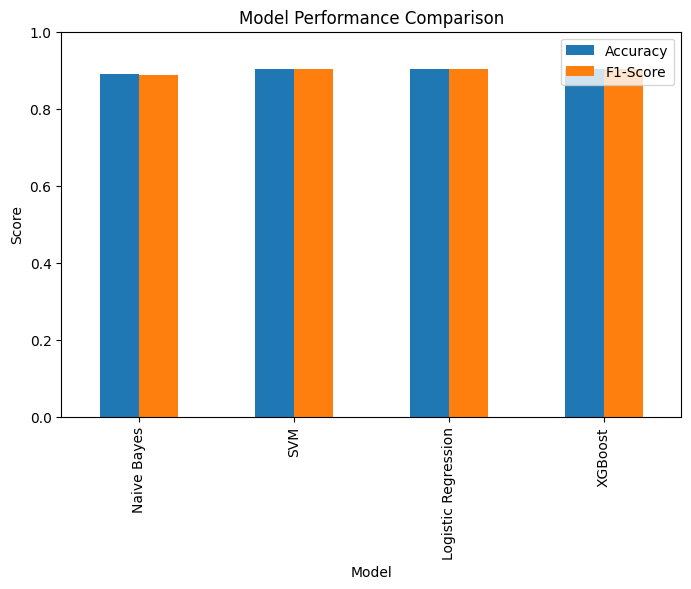

In [16]:
df_results.set_index("Model")[["Accuracy","F1-Score"]].plot(kind="bar", figsize=(8,5))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0,1)
plt.show()